In [1]:
#Read data
# Separate target
# Concatenate features
# Drop ID
# Check duplicates
#Check missing values
# Check skewness
# Check outliers
# Encode categorical variables
# Handle skewness 
#Scale 
#Train baseline models
#Hyperparameter tuning
#Final prediction

In [2]:
#importing everything needed
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df_train=pd.read_csv("Train_dataset.csv")
df_test=pd.read_csv("Test_dataset.csv")

In [4]:
#dropping the target from train
X_train= df_train.drop(["age_group"], axis=1)

In [95]:
y_train=df_train["age_group"]
# deleting the rows that have missing data in y train
mask = y_train.notna()
X_train = X_train.loc[mask].reset_index(drop=True)
y_train = y_train.loc[mask].reset_index(drop=True)

In [96]:
print(X_train.shape)
print(y_train.shape)

(1952, 9)
(1952,)


In [7]:
df=pd.concat([X_train,df_test],ignore_index=True)

BMXBMI Skewness: 1.36


<Figure size 100x100 with 0 Axes>

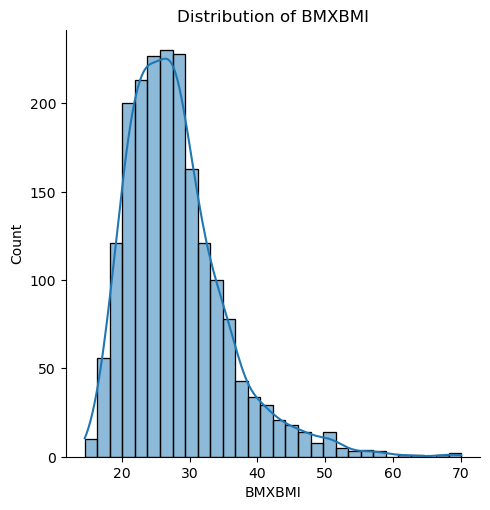

LBXGLU Skewness: 6.48


<Figure size 100x100 with 0 Axes>

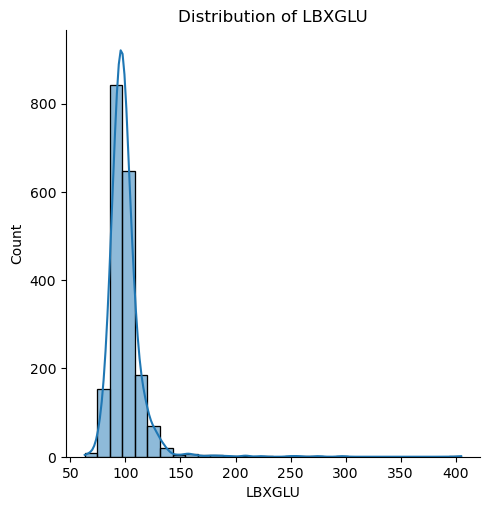

LBXGLT Skewness: 2.70


<Figure size 100x100 with 0 Axes>

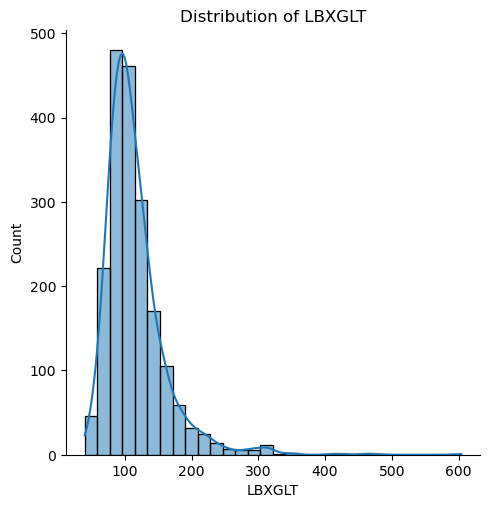

LBXIN Skewness: 2.71


<Figure size 100x100 with 0 Axes>

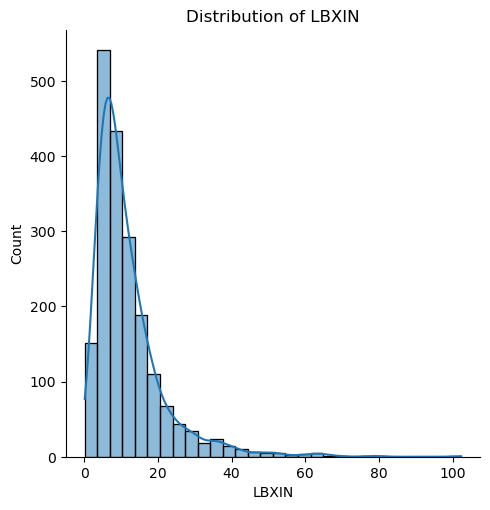

In [8]:
#checking if the data is skewed or not
numerical_cols = ['BMXBMI', 'LBXGLU', 'LBXGLT', 'LBXIN']

for col in numerical_cols:
    print(f"{col} Skewness: {df_train[col].skew():.2f}")
    plt.figure(figsize=(1,1))
    sns.displot(df_train[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.show()

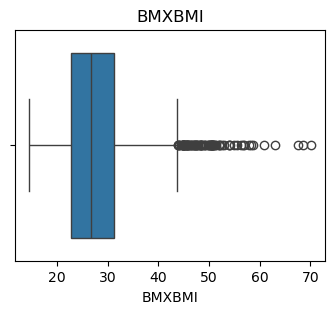

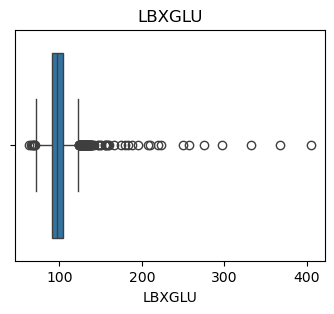

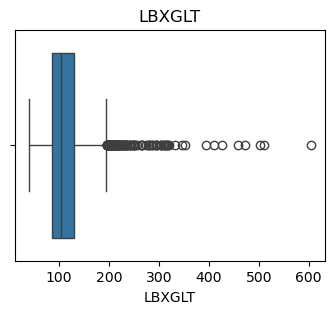

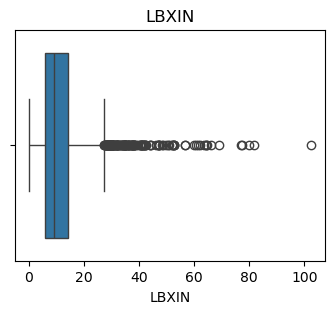

In [9]:
# checking for ouliers
for col in numerical_cols:
    plt.figure(figsize=(4,3))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

In [10]:
df[numerical_cols].describe()

,BMXBMI,LBXGLU,LBXGLT,LBXIN
count,2245.000000,2250.000000,2251.000000,2254.000000
mean,27.957506,99.549333,114.956020,11.846455
std,7.259069,17.898298,47.027966,9.748786
min,14.500000,63.000000,40.000000,0.140000
25%,22.800000,91.000000,86.500000,5.835000
50%,26.800000,97.000000,105.000000,9.040000
75%,31.200000,104.000000,130.000000,14.440000
max,70.100000,405.000000,604.000000,102.290000


In [11]:
# dropping id
df=df.drop('SEQN', axis=1)

In [12]:
# checking for missing values
df.isnull().sum()

RIAGENDR    20
PAQ605      14
BMXBMI      19
LBXGLU      14
DIQ010      19
LBXGLT      13
LBXIN       10
dtype: int64

In [13]:
print(df['PAQ605'].unique())

[ 2.  1. nan  7.]


In [14]:
print(df["DIQ010"].unique())

[ 2. nan  1.  3.]


In [88]:
df["DIQ010_3.0"].value_counts(dropna=False)

DIQ010_3.0
0    2208
1      56
Name: count, dtype: int64

In [15]:
#7 seems like a missing data, so removing itt
df['PAQ605'] = df['PAQ605'].replace(7, np.nan)
from sklearn.impute import SimpleImputer
imputer1 = SimpleImputer(strategy='median')
df[numerical_cols] = imputer1.fit_transform(df[numerical_cols])
cat_cols = ['RIAGENDR', 'PAQ605', 'DIQ010']
imputer2 = SimpleImputer(strategy='most_frequent')
df[cat_cols] = imputer2.fit_transform(df[cat_cols])

In [16]:
df.isnull().sum()

RIAGENDR    0
PAQ605      0
BMXBMI      0
LBXGLU      0
DIQ010      0
LBXGLT      0
LBXIN       0
dtype: int64

In [17]:
print(df['PAQ605'].value_counts(dropna=False))
print(df['PAQ605'].unique())

PAQ605
2.0    1860
1.0     404
Name: count, dtype: int64
[2. 1.]


In [18]:
# encoding
df['PAQ605'] = df['PAQ605'].map({1: 1, 2: 0})

In [19]:
df['RIAGENDR'] = df['RIAGENDR'].map({1: 0, 2: 1})

In [20]:
df = pd.get_dummies(df, columns=['DIQ010'], prefix='DIQ010', dtype=int)

In [21]:
print(df['PAQ605'].value_counts(dropna=False))

PAQ605
0    1860
1     404
Name: count, dtype: int64


In [89]:
df['INS_GLU_RATIO'] = df['LBXIN'] / (df['LBXGLU'] + 1)

In [112]:
#handling skewwwd data
cols_to_transform = ['BMXBMI', 'LBXGLU', 'LBXGLT', 'LBXIN']

for col in cols_to_transform:
    df[col] = np.log1p(df[col])

In [55]:
df = df.drop(columns=['RIAGENDR'])

In [91]:
X_train = df.iloc[:len(df_train)]
test = df.iloc[len(df_train):]

In [92]:
print(X_train.isnull().sum())

PAQ605           0
BMXBMI           0
LBXGLU           0
LBXGLT           0
LBXIN            0
DIQ010_1.0       0
DIQ010_2.0       0
DIQ010_3.0       0
INS_GLU_RATIO    0
dtype: int64


In [93]:
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

In [97]:
print(X_train.shape)
print(y_train.shape)

(1952, 9)
(1952,)


In [98]:
print(y_train.isnull().sum())

0


In [113]:
from sklearn.model_selection import train_test_split

X_train_final, X_test, y_train_final, y_test = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,

    stratify=y_train
)

In [114]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled = scaler.transform(X_test)

In [115]:
def find_score(model,X_train_final,X_test,y_train_final,y_test):
    model.fit(X_train_final, y_train_final)
    return model.score(X_test,y_test)

In [102]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(
    
    max_iter=5000,
    random_state=42
)
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier()
from sklearn.svm import SVC
svm = SVC(random_state=42)
from sklearn.neural_network import MLPClassifier
mlp = MLPClassifier(random_state=42, max_iter=1500)

In [69]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
from sklearn.ensemble import AdaBoostClassifier

ada = AdaBoostClassifier(random_state=42)
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42)
from xgboost import XGBClassifier

xgb = XGBClassifier(random_state=42)


In [116]:
find_score(dt,X_train_final,X_test,y_train_final,y_test)

0.6982097186700768

In [117]:
find_score(rf,X_train_final,X_test,y_train_final,y_test)

0.8260869565217391

In [105]:
find_score(ada,X_train_final,X_test,y_train_final,y_test)

0.8312020460358056

In [106]:
find_score(gb,X_train_final,X_test,y_train_final,y_test)

0.8312020460358056

In [107]:
find_score(lr,X_train_scaled,X_test_scaled,y_train_final,y_test)

0.8388746803069054

In [108]:
find_score(knn,X_train_scaled,X_test_scaled,y_train_final,y_test)

0.8056265984654731

In [109]:
find_score(svm,X_train_scaled,X_test_scaled,y_train_final,y_test)

0.8388746803069054

In [110]:
from sklearn.model_selection import cross_val_score
cross_val_score(SVC(),X_train_scaled,y_train_final)

array([0.8370607 , 0.83974359, 0.83974359, 0.83974359, 0.83974359])

In [118]:
find_score(mlp,X_train_scaled,X_test_scaled,y_train_final,y_test)

0.8388746803069054

In [79]:
print(y_train_final.value_counts())
print(y_train_final.value_counts(normalize=True))

age_group
Adult     1310
Senior     251
Name: count, dtype: int64
age_group
Adult     0.839206
Senior    0.160794
Name: proportion, dtype: float64


In [125]:
from sklearn.metrics import classification_report

y_pred = dt.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       Adult       0.83      0.80      0.82       328
      Senior       0.13      0.16      0.14        63

    accuracy                           0.70       391
   macro avg       0.48      0.48      0.48       391
weighted avg       0.72      0.70      0.71       391



In [82]:
import pandas as pd

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_final, y_train_final)

importance = pd.Series(
    rf.feature_importances_,
    index=X_train_final.columns
).sort_values(ascending=False)

print(importance)

LBXIN         0.279596
BMXBMI        0.261511
LBXGLT        0.236005
LBXGLU        0.197773
PAQ605        0.015341
DIQ010_1.0    0.004021
DIQ010_2.0    0.003250
DIQ010_3.0    0.002503
dtype: float64


In [83]:
X_train_new = X_train_final.drop(
    columns=['DIQ010_1.0', 'DIQ010_2.0', 'DIQ010_3.0']
)

X_test_new = X_test.drop(
    columns=['DIQ010_1.0', 'DIQ010_2.0', 'DIQ010_3.0']
)

In [84]:
from sklearn.model_selection import train_test_split

X_train_new, X_test_new, y_train_final, y_test = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [85]:
find_score(gb,X_train_new,X_test_new,y_train_final,y_test)

0.8312020460358056

In [126]:
from sklearn.metrics import f1_score

print(f1_score(y_test, y_pred, pos_label='Senior'))

0.14492753623188406


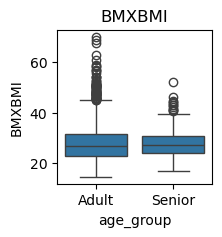

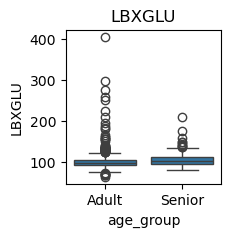

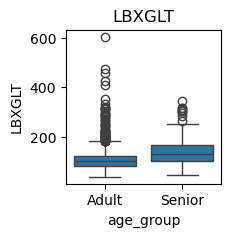

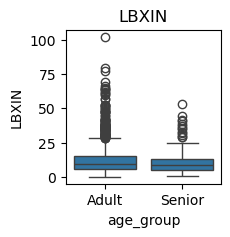

In [128]:
import seaborn as sns
import matplotlib.pyplot as plt

cols = ['BMXBMI', 'LBXGLU', 'LBXGLT', 'LBXIN']

for col in cols:
    plt.figure(figsize=(2,2))
    sns.boxplot(x='age_group', y=col, data=df_train)
    plt.title(col)
    plt.show()

In [1]:
!pip install mlxtend

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 11.4 MB/s  0:00:00
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -------------- ------------------------- 3.4/9.3 MB 18.6 MB/s eta 0:00:01
   ---------------------------- ----------- 6.6/9.3 MB 16.3 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 15.7 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 15.1 MB/s  0:00:00
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ---------------- ----------------------- 3.4/8.2 MB 17.7 MB/s eta 0:00:01
   ---------------------------------- ----- 7.1/8.2 MB 17.7 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 16.3 MB/s  0:00:00

  Attempting uninstall: scikit-learn

    Found existing installation: scikit-learn 1.7.2

   ---------------------------------------- 0/3 [scikit-learn]
   ----------------------------